## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

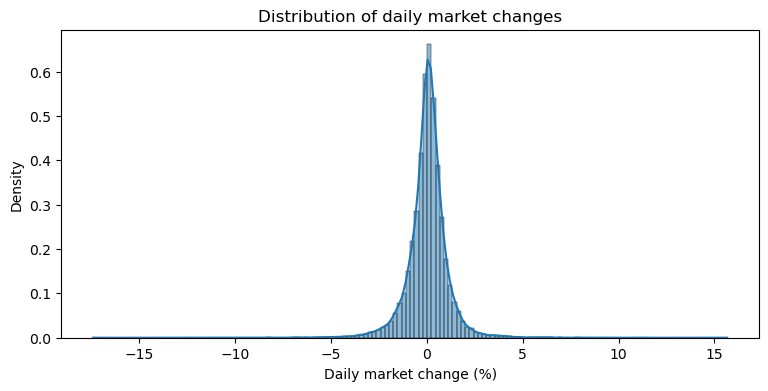

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

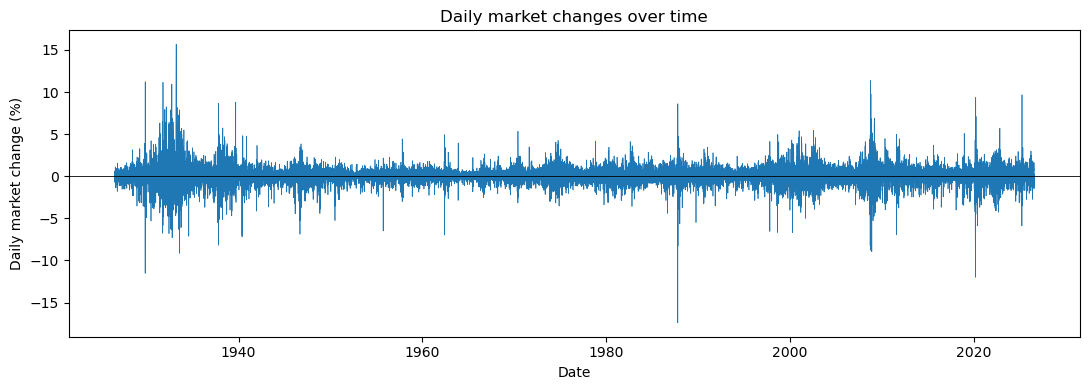

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [7]:
df['r_t'] = df['market_return_pct']
df['r_tp1'] = df['market_return_pct'].shift(-1)

two_state = df[['date', 'r_t', 'r_tp1']].dropna().copy()
two_state['state_t'] = np.where(two_state['r_t'] > 0, 'Up', 'Down')
two_state['state_tp1'] = np.where(two_state['r_tp1'] > 0, 'Up', 'Down')

two_state.head()

,date,r_t,r_tp1,state_t,state_tp1
0,1926-07-01,0.10,0.46,Up,Up
1,1926-07-02,0.46,0.18,Up,Up
2,1926-07-06,0.18,0.10,Up,Up
3,1926-07-07,0.10,0.23,Up,Up
4,1926-07-08,0.23,-0.70,Up,Down


In [8]:
states = ['Down', 'Up']

counts = pd.crosstab(
    two_state['state_t'],
    two_state['state_tp1']
).reindex(index=states, columns=states, fill_value=0)

joint_pmf = counts / counts.to_numpy().sum()

marginals = pd.DataFrame({
    'Current day': joint_pmf.sum(axis=1),
    'Next trading day': joint_pmf.sum(axis=0)
})

conditional_pmf = counts.div(counts.sum(axis=1), axis=0)

print('Transition counts:')
display(counts)

print('Joint PMF:')
display(joint_pmf)

print('Marginal PMFs:')
display(marginals)

print('Conditional PMF:')
display(conditional_pmf)

Transition counts:


state_tp1,Down,Up
state_t,,
Down,5909,5999
Up,5999,8388


Joint PMF:


state_tp1,Down,Up
state_t,,
Down,0.224720,0.228142
Up,0.228142,0.318996


Marginal PMFs:


,Current day,Next trading day
Down,0.452862,0.452862
Up,0.547138,0.547138


Conditional PMF:


state_tp1,Down,Up
state_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


- Up transitions are more common than Down transitions. The next trading day is Up in about 54.71% of the observed pairs and Down or flat in 45.29%.
- An Up day is more likely after an Up day than after a Down day. P(Up tomorrow|Up today)=58.30%, compared with P(Up tomorrow|text{Down today})=50.38%. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [ ]:
bins_5 = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels_5 = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['state_5_t'] = pd.cut(df['market_return_pct'], bins=bins_5, labels=labels_5, right=True)
df['state_5_tp1'] = df['state_5_t'].shift(-1)

bin_counts = df['state_5_t'].value_counts(sort=False)
display(bin_counts.to_frame(name='Number of days'))

five_state = df[['date', 'r_t', 'r_tp1', 'state_5_t', 'state_5_tp1']].dropna().copy()
display(five_state.head())

,Number of days
state_5_t,
Large loss,2759
Small loss,7452
Near zero,3441
Small gain,9785
Large gain,2859


,date,r_t,r_tp1,state_5_t,state_5_tp1
0,1926-07-01,0.10,0.46,Near zero,Small gain
1,1926-07-02,0.46,0.18,Small gain,Small gain
2,1926-07-06,0.18,0.10,Small gain,Near zero
3,1926-07-07,0.10,0.23,Near zero,Small gain
4,1926-07-08,0.23,-0.70,Small gain,Small loss


In [12]:
counts_5 = pd.crosstab(five_state['state_5_t'],five_state['state_5_tp1']
                       ).reindex(index=labels_5, columns=labels_5, fill_value=0)

joint_5 = counts_5 / counts_5.to_numpy().sum()

marginals_5 = pd.DataFrame({
    'Current day': joint_5.sum(axis=1),
    'Next trading day': joint_5.sum(axis=0)
})

conditional_5 = counts_5.div(counts_5.sum(axis=1), axis=0)

print('Joint PMF:')
display(joint_5)

print('Marginal PMFs:')
display(marginals_5)

print('Conditional PMF:')
display(conditional_5)

Joint PMF:


state_5_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
state_5_t,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


Marginal PMFs:


,Current day,Next trading day
Large loss,0.104925,0.104925
Small loss,0.283400,0.283400
Near zero,0.130861,0.130823
Small gain,0.372086,0.372124
Large gain,0.108728,0.108728


Conditional PMF:


state_5_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
state_5_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


- The five categories contain 2,759 Large loss days, 7,452 Small loss days, 3,441 Near zero days, 9,785 Small gain days, and 2,859 Large gain days. Small gain is the most common category, while Large loss is the least common.

- The most common transition is Small gain to Small gain, 15.94% of all observed transitions. 

- Current state: Large loss, 1st Most: Small gain (26.50%), 2nd Most: Small loss (25.92%) 

Current state: Small loss, 1st Most: Small gain (34.50%), 2nd Most: Small loss (31.28%)

Current state: Near zero, 1st Most: Small gain (37.69%), 2nd Most: Small loss (32.08%)

Current state: Small gain, 1st Most: Small gain (42.85%), 2nd Most: Small loss (26.89%)

Current state: Large gain, 1st Most: Small gain (34.77%), 2nd Most: Small loss (23.47%)

The Large loss row is relatively closest to uniform, although Near zero is much less likely than 20%. The other rows are less uniform, especially the Small gain row. However, predicting the next state remains difficult because no row assigns a high probability to a single outcome.

In [ ]:
next_return_summary = (five_state.groupby('state_5_t', observed=True)['r_tp1'].describe())
next_return_summary

,count,mean,std,min,25%,50%,75%,max
state_5_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


- The estimated mean tomorrow returns are −0.0383%(Large loss), −0.0438%(Small loss), 0.0150%(Near zero), 0.1068%(Small gain), and 0.1631%(Large gain). Following Large loss days, tomorrow returns range from −17.41% to 11.22%; following Large gain days, they range from −12.00% to 15.67%. These ranges are wider than those following Near zero or Small gain days. Tomorrow return's volatility is highest after Large loss days (standard deviation 1.7206 percentage points), followed by Large gain days (1.3841). It is lowest after Near zero days (0.8261). This suggests volatility clustering. Large movements tend to be followed by more volatile days, without necessarily continuing in the same direction.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [18]:
df = df.sort_values('date').reset_index(drop=True)

n_bins = 21
states_21 = list(range(n_bins))

df['y_t'] = pd.qcut(df['market_return_pct'],q=n_bins,labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df['r_tp1'] = df['market_return_pct'].shift(-1)

pairs_21 = df[['y_t', 'y_tp1', 'r_tp1']].dropna().copy()
pairs_21[['y_t', 'y_tp1']] = (pairs_21[['y_t', 'y_tp1']].astype(int))

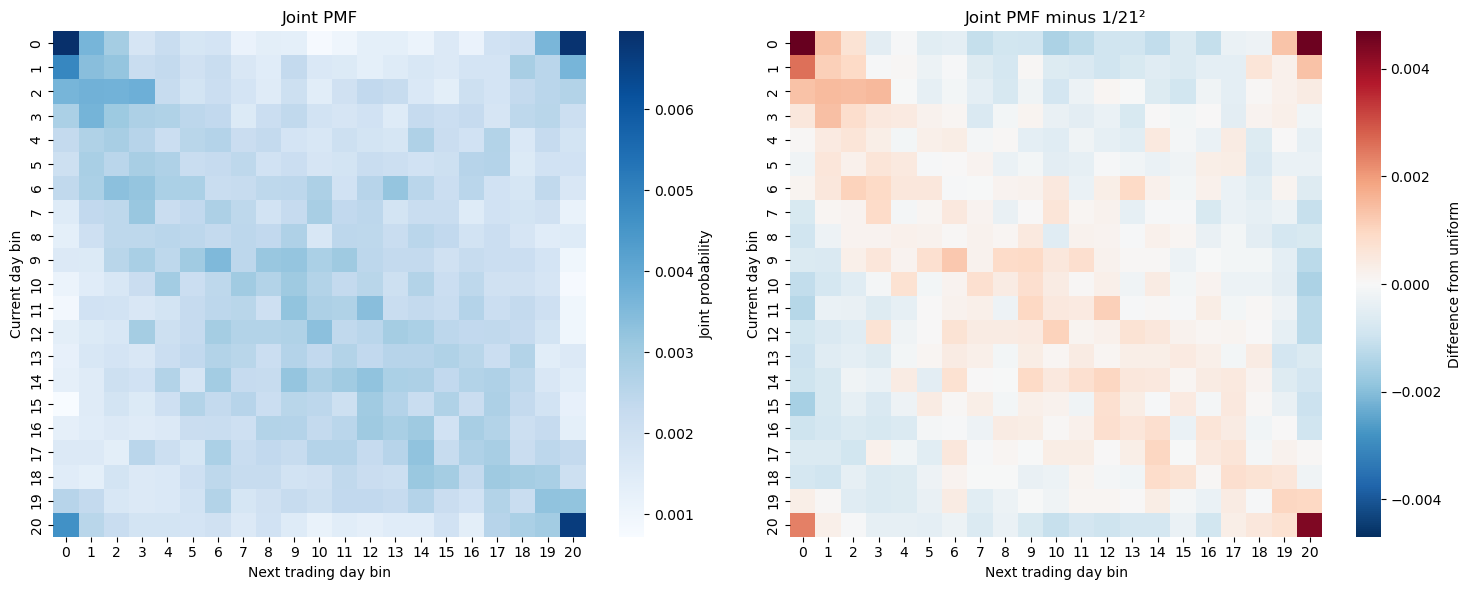

In [19]:
counts_21 = pd.crosstab(pairs_21['y_t'],pairs_21['y_tp1']
                        ).reindex(index=states_21, columns=states_21, fill_value=0)

joint_21 = counts_21 / counts_21.to_numpy().sum()

joint_deviation = joint_21 - 1 / (n_bins**2)
joint_limit = np.abs(joint_deviation.to_numpy()).max()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    joint_21,
    cmap='Blues',
    ax=axes[0],
    cbar_kws={'label': 'Joint probability'}
)
axes[0].set_title('Joint PMF')

sns.heatmap(
    joint_deviation,
    cmap='RdBu_r',
    center=0,
    vmin=-joint_limit,
    vmax=joint_limit,
    ax=axes[1],
    cbar_kws={'label': 'Difference from uniform'}
)
axes[1].set_title('Joint PMF minus 1/21²')

for ax in axes:
    ax.set_xlabel('Next trading day bin')
    ax.set_ylabel('Current day bin')

plt.tight_layout()
plt.show()

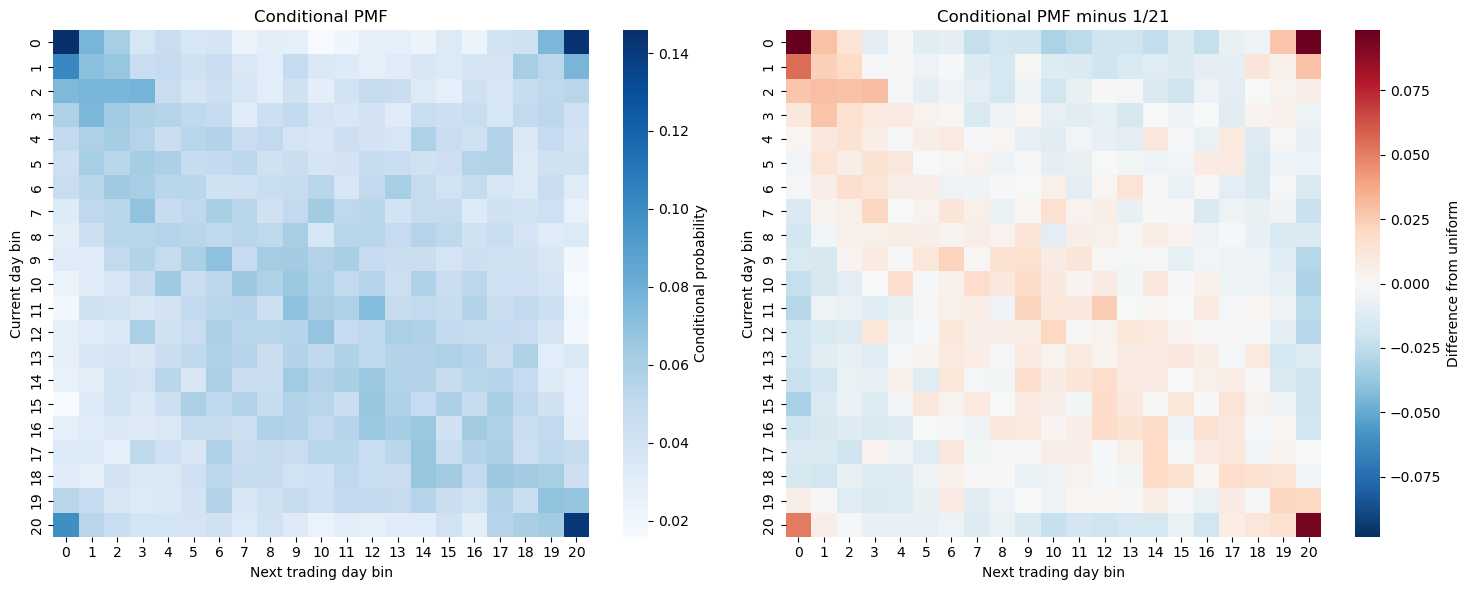

In [ ]:
conditional_21 = counts_21.div(
    counts_21.sum(axis=1),
    axis=0
)

conditional_deviation = conditional_21 - 1 / n_bins
conditional_limit = np.abs(conditional_deviation.to_numpy()).max()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    conditional_21,
    cmap='Blues',
    ax=axes[0],
    cbar_kws={'label': 'Conditional probability'}
)
axes[0].set_title('Conditional PMF')

sns.heatmap(
    conditional_deviation,
    cmap='RdBu_r',
    center=0,
    vmin=-conditional_limit,
    vmax=conditional_limit,
    ax=axes[1],
    cbar_kws={'label': 'Difference from uniform'}
)
axes[1].set_title('Conditional PMF minus 1/21')

for ax in axes:
    ax.set_xlabel('Next trading day bin')
    ax.set_ylabel('Current day bin')

plt.tight_layout()
plt.show()

,min,mean,max,std
y_t,,,,
0,-17.41,-0.013713,11.22,2.140465
1,-7.36,-0.076712,6.36,1.285882
2,-8.79,-0.097084,11.36,1.227976
3,-8.28,-0.058594,6.16,1.049607
4,-6.89,-0.024211,4.56,0.989470
5,-11.23,-0.022692,6.37,1.024761
6,-3.94,-0.030241,7.37,0.930389
7,-3.40,-0.014303,4.76,0.835663
8,-6.00,0.025860,5.49,0.853220


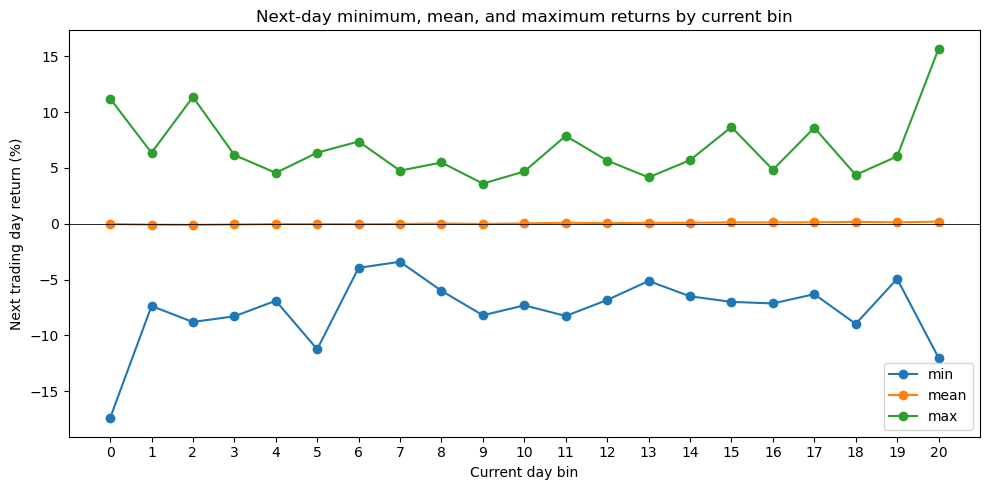

In [21]:
summary_21 = (pairs_21.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max', 'std']).reindex(states_21))
display(summary_21)

fig, ax = plt.subplots(figsize=(10, 5))

for statistic in ['min', 'mean', 'max']:
    ax.plot(
        summary_21.index,
        summary_21[statistic],
        marker='o',
        label=statistic
    )

ax.axhline(0, color='black', linewidth=0.6)
ax.set(
    xlabel='Current day bin',
    ylabel='Next trading day return (%)',
    title='Next-day minimum, mean, and maximum returns by current bin'
)
ax.set_xticks(states_21)
ax.legend()

fig.tight_layout()
plt.show()

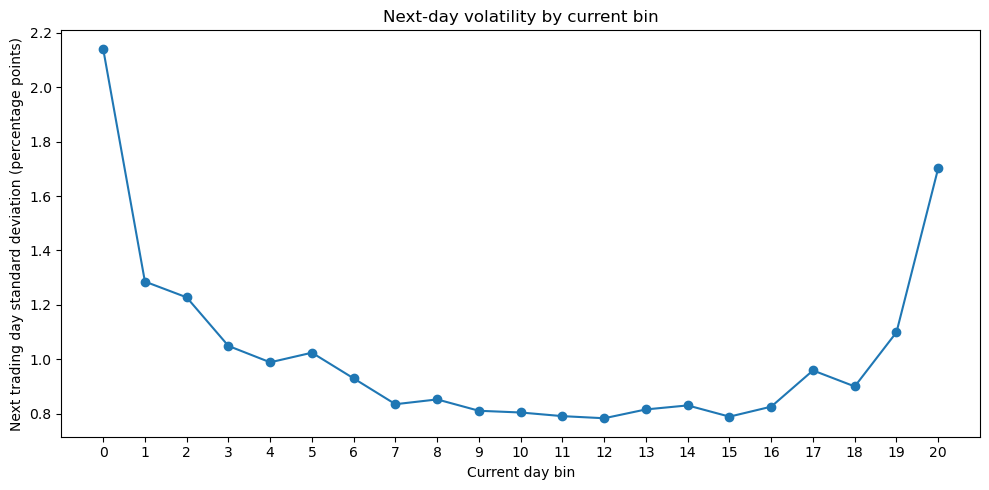

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    summary_21.index,
    summary_21['std'],
    marker='o'
)

ax.set(
    xlabel='Current day bin',
    ylabel='Next trading day standard deviation (percentage points)',
    title='Next-day volatility by current bin'
)
ax.set_xticks(states_21)

fig.tight_layout()
plt.show()

- The corner cells have high probabilities, showing that extreme returns are often followed by other extreme returns, both positive and negative. Subtracting 1/21^2 makes these patterns clearer, extreme to extreme combinations occur more frequently than under the uniform benchmark. This suggests volatility clustering.
- The next day distribution depends on the current bin. After extreme negative or positive returns, extreme next day returns are more likely than the uniform probability of 1/21. After moderate returns, extreme outcomes are generally less likely. 
- Mean next day returns remain close to zero compared with the much larger positive and negative extremes. The lowest current bin has the most negative next day minimum, while the highest current bin has the largest next day maximum. However, the minimum and maximum lines fluctuate considerably across bins.
- Next day standard deviation is highest after returns in the lowest bin and second highest after returns in the highest bin, while middle bins have lower volatility. This supports volatility clustering, large market movements tend to be followed by more volatile trading days.
- Predicting the exact next day return or its direction is difficult. Conditional means are small relative to the variability of returns, and the transition probabilities remain spread across many states. These results suggest that today's return provides more useful information about tomorrow's volatility than about its direction.